# GCN vs GAT on OGBN-Arxiv

The dataset notebook studied the data. This notebook runs the experiments.

**The question:** does the way a model mixes neighbour information change accuracy and speed?

**The one difference between GCN and GAT:**

| | GCN | GAT |
|---|---|---|
| Weight of a neighbour | fixed, from degree | learned, from features |
| Can it treat neighbours differently? | no | yes |

**What we run:**

- **Accuracy** — MLP vs GCN vs GAT, over a few seeds
- **Damage** — add fake edges and remove real edges, at several levels
- **Homophily** — how the damage changes the graph
- **Attention** — look inside GAT: does it give fake edges a smaller weight?

**Why the MLP:** it ignores the graph and uses only the text features. It tells us how much the
graph helps at all.

**Our Hypothesis (only guesses, not facts):**

- GAT *may* be more accurate, because it learns a weight per neighbour
- GAT *should* be slower, because attention works on every edge
- GAT *may* lose less under damage, if it learns to ignore fake edges


**You need a GPU.** On Colab: Runtime -> Change runtime type -> T4 GPU.
If you still run out of memory, lower `HIDDEN` to 64 and `HEADS` to 2.

## Setup

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q ogb torch_geometric

print("Colab:", IN_COLAB)

Colab: True


In [2]:
import time
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv

# Newer PyTorch needs this to open the file OGB saved.
_original_load = torch.load
torch.load = lambda *a, **k: _original_load(*a, **{**k, "weights_only": False})

from ogb.nodeproppred import NodePropPredDataset

print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cu128


### Seeds

Two things in training are random: the starting weights and the dropout. A seed fixes both, so the
same seed gives the same result. Different seeds give slightly different results, which is why we
run several later.

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                 # controls the CPU random numbers
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)    # controls the GPU random numbers


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU   :", torch.cuda.get_device_name(0))

Device: cuda
GPU   : Tesla T4


## Load the data

- a node is a paper
- an edge is a citation
- 40 classes, one subject per paper

In [4]:
dataset = NodePropPredDataset(name="ogbn-arxiv", root="./data")
graph, labels = dataset[0]
split = dataset.get_idx_split()

features_np = graph["node_feat"]
num_nodes = int(graph["num_nodes"])
num_features = int(features_np.shape[1])
num_classes = int(labels.max()) + 1
y_np = labels.reshape(-1)

print("nodes   :", f"{num_nodes:,}")
print("edges   :", f"{graph['edge_index'].shape[1]:,}")
print("features:", num_features)
print("classes :", num_classes)


nodes   : 169,343
edges   : 1,166,243
features: 128
classes : 40


## Build the graph

Two things happen here.

**We make the graph undirected.** A citation points one way. If we keep the arrows, a new paper that
nobody has cited yet gets no messages from its neighbours. The test papers are the newest ones, so
this would hurt. For every edge `u -> v` we also add `v -> u`. Both models get the same graph.

What we lose: the direction information. We accept that, and we write it down.

**We convert NumPy to PyTorch.**

- features -> `.float()`, because the model uses float weights
- labels -> `.long().view(-1)`, because the loss wants class numbers in a flat list
- edges -> `.long()`, because index lists must be int64

In [5]:
source = graph["edge_index"][0].astype(np.int64)
target = graph["edge_index"][1].astype(np.int64)


small = np.minimum(source, target)
big = np.maximum(source, target)
keep = small != big
base_edges = np.unique(small[keep] * num_nodes + big[keep])

print("undirected edges:", f"{len(base_edges):,}")


def build_data(edge_keys):
    u = edge_keys // num_nodes
    v = edge_keys % num_nodes
    src = np.concatenate([u, v])          # both directions
    dst = np.concatenate([v, u])

    x = torch.from_numpy(features_np).float()
    y = torch.from_numpy(labels).long().view(-1)
    edge_index = torch.from_numpy(np.stack([src, dst])).long()
    return Data(x=x, y=y, edge_index=edge_index, num_nodes=num_nodes)


def homophily(edge_keys):
    # share of edges where both papers have the same subject
    u = edge_keys // num_nodes
    v = edge_keys % num_nodes
    return float((y_np[u] == y_np[v]).mean())


data = build_data(base_edges).to(device)
split_idx = {k: torch.from_numpy(split[k]).long().to(device) for k in split}

print(data)
for k in split_idx:
    print(f"  {k:6s}: {len(split_idx[k]):,} nodes")
print()
print("homophily of the clean graph:", round(homophily(base_edges), 4))

undirected edges: 1,157,799
Data(x=[169343, 128], edge_index=[2, 2315598], y=[169343], num_nodes=169343)
  train : 90,941 nodes
  valid : 29,799 nodes
  test  : 48,603 nodes

homophily of the clean graph: 0.6542


## Settings

Everything we can change is here.

Start with `QUICK = True` to check the code runs. Then set it to `False` for real numbers.

In [6]:

HIDDEN = 128          # width of the hidden layer (same for all models)
HEADS = 4             # attention heads in GAT
LR = 0.005
DROPOUT = 0.5
EPOCHS = 300
PATIENCE = 100
SEEDS = [0, 1,2]
LEVELS = [0.05, 0.1, 0.2, 0.3]   # how much damage to try
NOISE_SEED = 1234     # decides which edges are added or removed


print("epochs:", EPOCHS, "| seeds:", SEEDS, "| damage levels:", LEVELS)

results = []          # one row per run, never deleted

epochs: 300 | seeds: [0, 1, 2] | damage levels: [0.05, 0.1, 0.2, 0.3]


## The three models

All three end with a layer of size 40, so we get one score per class per node.

- **MLP** — no graph, only the features
- **GCN** — mixes neighbours with a fixed weight
- **GAT** — mixes neighbours with a learned weight

**How attention works, in short:**

- for each edge, GAT looks at the two nodes and gives the edge a score
- the scores of one node's neighbours are turned into weights that add up to 1
- the neighbours are mixed using those weights

**The settings:**

- `heads` — how many attention mechanisms run side by side; more heads make training steadier
- `concat=True` joins the heads, `concat=False` averages them
- `dropout` inside `GATConv` drops some neighbour weights while training

**A fair-size choice:** each head has size `HIDDEN / HEADS`. With 4 heads of 32, joining them gives
128 — the same width as GCN. Without this GAT would be 4 times wider, and any gain could just mean
"bigger model".

In [7]:
class MLP(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = torch.nn.Linear(num_features, HIDDEN)
        self.layer2 = torch.nn.Linear(HIDDEN, num_classes)

    def forward(self, x, edge_index):          # edge_index is ignored on purpose
        x = F.relu(self.layer1(x))
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.layer2(x)


class GCN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = GCNConv(num_features, HIDDEN)
        self.layer2 = GCNConv(HIDDEN, num_classes)

    def forward(self, x, edge_index):
        x = self.layer1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=DROPOUT, training=self.training)   # dropout only while training
        return self.layer2(x, edge_index)


class GAT(torch.nn.Module):
    def __init__(self):
        super().__init__()
        head_size = HIDDEN // HEADS
        self.layer1 = GATConv(num_features, head_size, heads=HEADS, concat=True, dropout=DROPOUT)
        self.layer2 = GATConv(HIDDEN, num_classes, heads=HEADS, concat=False, dropout=DROPOUT)

    def forward(self, x, edge_index, return_attention=False):
        if return_attention:
            # ask the layers to also hand back the weight they gave to every edge
            x, att1 = self.layer1(x, edge_index, return_attention_weights=True)
            x = F.elu(x)
            out, att2 = self.layer2(x, edge_index, return_attention_weights=True)
            return out, [att1, att2]
        x = self.layer1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=DROPOUT, training=self.training)
        return self.layer2(x, edge_index)


MODELS = {"MLP": MLP, "GCN": GCN, "GAT": GAT}

for name in MODELS:
    n = sum(p.numel() for p in MODELS[name]().parameters())
    print(f"{name}: {n:,} parameters")

MLP: 21,672 parameters
GCN: 21,672 parameters
GAT: 37,608 parameters


## One training function for every model

Same optimizer, same learning rate, same dropout, same epochs, same stopping rule. So a difference
in the result comes from the model, not from the setup.

**How we pick the best model:** after each epoch we check the validation accuracy and keep a copy of
the best weights. At the very end we load them and check the test accuracy once.

In [8]:
@torch.no_grad()                    # no gradients needed here -> faster
def get_accuracy(model, data, split_idx):
    model.eval()                    # eval mode: dropout off
    pred = model(data.x, data.edge_index).argmax(dim=1)
    return {k: float((pred[idx] == data.y[idx]).float().mean()) for k, idx in split_idx.items()}


def train(model_name, data, seed, graph_name="clean", level=0.0):
    set_seed(seed)
    model = MODELS[model_name]().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    train_idx = split_idx["train"]
    best_valid, best_epoch, best_weights, waited = -1, 0, None, 0

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()                                   # train mode: dropout on
        optimizer.zero_grad()                           # clear old gradients
        out = model(data.x, data.edge_index)            # forward pass
        loss = F.cross_entropy(out[train_idx], data.y[train_idx])   # loss on train nodes only
        loss.backward()                                 # find the gradients
        optimizer.step()                                # update the weights

        acc = get_accuracy(model, data, split_idx)
        if acc["valid"] > best_valid:
            best_valid, best_epoch, waited = acc["valid"], epoch, 0
            # keep a copy of the best weights (on CPU, to save GPU memory)
            best_weights = copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})
        else:
            waited += 1
            if waited >= PATIENCE:
                break                                   # early stopping

    if device.type == "cuda":
        torch.cuda.synchronize()                        # wait for the GPU, or timing is wrong
    total_time = time.time() - start

    model.load_state_dict(best_weights)                 # best weights, chosen by validation
    model.to(device)
    final = get_accuracy(model, data, split_idx)        # now we look at test, once

    row = {
        "model": model_name, "graph": graph_name, "level": level, "seed": seed,
        "test_acc": round(final["test"], 4), "valid_acc": round(best_valid, 4),
        "best_epoch": best_epoch, "epochs_run": epoch,
        "total_time": round(total_time, 1),
        "time_per_epoch": round(total_time / epoch, 4),
        "parameters": sum(p.numel() for p in model.parameters()),
    }
    results.append(row)
    return row, model

## First a test run

One model, one seed. We only check that the code works and that the accuracy beats guessing.
This is not a result.

In [9]:
row, _ = train("GCN", data, seed=0)
print(row)

assert row["test_acc"] > 1 / num_classes, "no better than guessing - something is wrong"
print("\nOK.")

{'model': 'GCN', 'graph': 'clean', 'level': 0.0, 'seed': 0, 'test_acc': 0.6774, 'valid_acc': 0.6908, 'best_epoch': 296, 'epochs_run': 300, 'total_time': 49.6, 'time_per_epoch': 0.1653, 'parameters': 21672}

OK.


## Accuracy and speed

- three models, a few seeds each
- we report the **average** and the **spread** (standard deviation)

**Why several seeds:** the starting weights are random, so one run can be lucky. If the gap between
two models is smaller than the spread, the experiment does not show a real difference.

In [10]:
for name in ["MLP", "GCN", "GAT"]:
    for seed in SEEDS:
        r, _ = train(name, data, seed)
        print(f"  {name}  seed {seed}:  test = {r['test_acc']:.4f}   time = {r['total_time']:.0f}s")

  MLP  seed 0:  test = 0.5234   time = 5s
  MLP  seed 1:  test = 0.5233   time = 5s
  MLP  seed 2:  test = 0.5227   time = 5s
  GCN  seed 0:  test = 0.6805   time = 53s
  GCN  seed 1:  test = 0.6777   time = 51s
  GCN  seed 2:  test = 0.6776   time = 52s
  GAT  seed 0:  test = 0.6844   time = 143s
  GAT  seed 1:  test = 0.6838   time = 143s
  GAT  seed 2:  test = 0.6844   time = 143s


In [11]:
df = pd.DataFrame(results)
clean = df[(df.graph == "clean") & (df.seed.isin(SEEDS))]

summary = clean.groupby("model").agg(
    mean_acc=("test_acc", "mean"),
    std_acc=("test_acc", "std"),
    mean_time=("total_time", "mean"),
    time_per_epoch=("time_per_epoch", "mean"),
    parameters=("parameters", "first"),
    runs=("seed", "count"),
).reindex(["MLP", "GCN", "GAT"]).reset_index()

print("ACCURACY AND SPEED (average over seeds, device:", str(device), ")")
print(summary.round(4).to_string(index=False))

ACCURACY AND SPEED (average over seeds, device: cuda )
model  mean_acc  std_acc  mean_time  time_per_epoch  parameters  runs
  MLP    0.5231   0.0004     4.9667          0.0166       21672     3
  GCN    0.6783   0.0015    51.3500          0.1712       21672     4
  GAT    0.6842   0.0003   142.6667          0.4755       37608     3


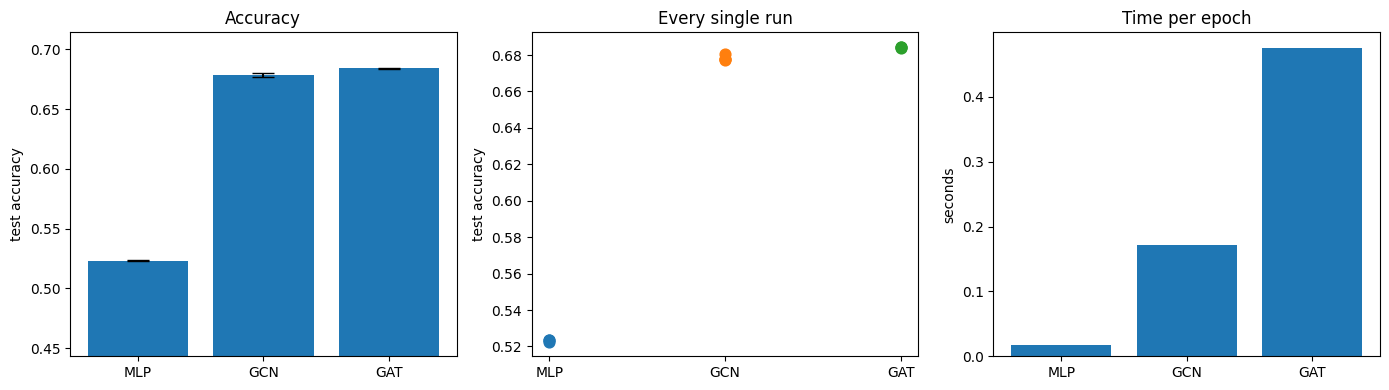

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].bar(summary["model"], summary["mean_acc"],
            yerr=np.nan_to_num(summary["std_acc"]), capsize=8)
axes[0].set_ylabel("test accuracy"); axes[0].set_title("Accuracy")
axes[0].set_ylim(summary["mean_acc"].min() - 0.08, summary["mean_acc"].max() + 0.03)

for i, m in enumerate(summary["model"]):
    points = clean[clean.model == m]["test_acc"].values
    axes[1].scatter([i] * len(points), points, s=60)
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(summary["model"])
axes[1].set_ylabel("test accuracy"); axes[1].set_title("Every single run")

axes[2].bar(summary["model"], summary["time_per_epoch"])
axes[2].set_ylabel("seconds"); axes[2].set_title("Time per epoch")

plt.tight_layout(); plt.show()

**How to read this:**

- MLP vs the others -> how much the graph helps
- GCN vs GAT -> whether learned weights help
- middle plot -> if the dots overlap, there is no clear winner
- right plot -> model size and speed are different things; attention costs extra time even when the
  model size is similar

## Damage the graph

Real graphs are never perfect. So we damage this one on purpose and see which model suffers more.

**We only change the edges.** Features, labels and the split stay the same. So any change in
accuracy comes from the structure.

**Adding fake edges** — we connect random pairs of papers. Random pairs are usually from different
subjects, so these edges are noise. The model gets **wrong** information.

**Removing real edges** — we delete existing edges at random. The model gets **less** information,
but nothing wrong.

**What "10%" means:** 10% of the number of edges in the original graph.

**Two separate random choices:**

- `NOISE_SEED` decides which edges are added or removed
- the model seed decides the starting weights

For each level we build the damaged graph **once** and give the same one to GCN and GAT. If each
model got its own graph, a difference could just mean one model got an easier graph.

In [13]:
def damage_graph(edge_keys, kind, level, seed):
    # Returns the new edge list, and the fake edges we added (empty when removing).
    rng = np.random.default_rng(seed)
    how_many = int(level * len(edge_keys))

    if kind == "remove":
        keep_these = rng.permutation(len(edge_keys))[how_many:]   # shuffle, drop the first few
        return np.sort(edge_keys[keep_these]), np.array([], dtype=np.int64)

    # kind == "add"
    collected = []
    needed = how_many
    while needed > 0:
        a = rng.integers(0, num_nodes, size=needed * 2 + 10)      # pick extra, some get rejected
        b = rng.integers(0, num_nodes, size=needed * 2 + 10)
        lo = np.minimum(a, b).astype(np.int64)
        hi = np.maximum(a, b).astype(np.int64)
        cand = np.unique(lo[lo != hi] * num_nodes + hi[lo != hi])  # no self-loops, no repeats
        cand = cand[~np.isin(cand, edge_keys)]                     # not already in the graph
        if collected:
            cand = cand[~np.isin(cand, np.concatenate(collected))]
        chosen = cand[:needed]
        if len(chosen) > 0:
            collected.append(chosen)
            needed -= len(chosen)

    fake = np.concatenate(collected)
    return np.sort(np.concatenate([edge_keys, fake])), fake

In [14]:
# Check the function on a tiny made-up graph before using it on the real one.
test_n = 100
test_rng = np.random.default_rng(0)
a, b = test_rng.integers(0, test_n, 400), test_rng.integers(0, test_n, 400)
lo, hi = np.minimum(a, b), np.maximum(a, b)
test_edges = np.unique(lo[lo != hi].astype(np.int64) * test_n + hi[lo != hi])

real_num_nodes = num_nodes
num_nodes = test_n                                  # the function uses num_nodes
bigger, fake = damage_graph(test_edges, "add", 0.2, 5)
smaller, _ = damage_graph(test_edges, "remove", 0.2, 5)
again, _ = damage_graph(test_edges, "add", 0.2, 5)
num_nodes = real_num_nodes                          # put it back

assert len(bigger) == len(test_edges) + len(fake)
assert len(np.unique(bigger)) == len(bigger), "a duplicate edge was made"
assert np.isin(test_edges, bigger).all(), "an old edge disappeared"
assert np.isin(smaller, test_edges).all(), "a new edge appeared"
assert np.array_equal(bigger, again), "same seed gave a different graph"

print("damage function works:", len(test_edges), "edges ->",
      len(bigger), "after adding,", len(smaller), "after removing")

damage function works: 377 edges -> 452 after adding, 302 after removing


In [15]:
graph_info = []       # homophily and size of each damaged graph
fake_edges_at = {}    # keep the fake edges of each level, for the attention part

for kind in ["add", "remove"]:
    for level in LEVELS:
        damaged_edges, fake = damage_graph(base_edges, kind, level, NOISE_SEED)
        graph_info.append({"kind": kind, "level": level, "edges": len(damaged_edges),
                           "homophily": round(homophily(damaged_edges), 4)})
        if kind == "add":
            fake_edges_at[level] = fake

        damaged_data = build_data(damaged_edges).to(device)     # one graph, both models

        for name in ["GCN", "GAT"]:
            for seed in SEEDS:
                r, _ = train(name, damaged_data, seed, graph_name=kind, level=level)
                print(f"  {kind:6s} {level:.0%}  {name}  seed {seed}:  test = {r['test_acc']:.4f}")

        del damaged_data
        if device.type == "cuda":
            torch.cuda.empty_cache()

# the clean graph counts as level 0 for both kinds
for kind in ["add", "remove"]:
    graph_info.append({"kind": kind, "level": 0.0, "edges": len(base_edges),
                       "homophily": round(homophily(base_edges), 4)})

graph_table = pd.DataFrame(graph_info).sort_values(["kind", "level"])
print()
print(graph_table.to_string(index=False))

  add    5%  GCN  seed 0:  test = 0.6618
  add    5%  GCN  seed 1:  test = 0.6637
  add    5%  GCN  seed 2:  test = 0.6602
  add    5%  GAT  seed 0:  test = 0.6689
  add    5%  GAT  seed 1:  test = 0.6674
  add    5%  GAT  seed 2:  test = 0.6700
  add    10%  GCN  seed 0:  test = 0.6492
  add    10%  GCN  seed 1:  test = 0.6538
  add    10%  GCN  seed 2:  test = 0.6500
  add    10%  GAT  seed 0:  test = 0.6585
  add    10%  GAT  seed 1:  test = 0.6570
  add    10%  GAT  seed 2:  test = 0.6591
  add    20%  GCN  seed 0:  test = 0.6358
  add    20%  GCN  seed 1:  test = 0.6363
  add    20%  GCN  seed 2:  test = 0.6340
  add    20%  GAT  seed 0:  test = 0.6430
  add    20%  GAT  seed 1:  test = 0.6406
  add    20%  GAT  seed 2:  test = 0.6454
  add    30%  GCN  seed 0:  test = 0.6201
  add    30%  GCN  seed 1:  test = 0.6222
  add    30%  GCN  seed 2:  test = 0.6206
  add    30%  GAT  seed 0:  test = 0.6327
  add    30%  GAT  seed 1:  test = 0.6292
  add    30%  GAT  seed 2:  test = 0.629

## How much did each model lose?

- **drop** = clean accuracy minus damaged accuracy
- **lost %** = drop divided by clean accuracy

The percentage is the fairer one. A model that starts higher can lose more points and still be in
the same place.

In [16]:
df = pd.DataFrame(results)
clean_acc = clean.groupby("model")["test_acc"].mean().to_dict()

rows = []
for kind in ["add", "remove"]:
    for name in ["GCN", "GAT"]:
        rows.append({"kind": kind, "model": name, "level": 0.0,
                     "mean_acc": round(clean_acc[name], 4), "std_acc": 0.0,
                     "drop": 0.0, "lost_percent": 0.0})
        for level in LEVELS:
            part = df[(df.graph == kind) & (df.level == level) & (df.model == name)]["test_acc"]
            drop = clean_acc[name] - part.mean()
            rows.append({"kind": kind, "model": name, "level": level,
                         "mean_acc": round(part.mean(), 4),
                         "std_acc": round(part.std(), 4),
                         "drop": round(drop, 4),
                         "lost_percent": round(100 * drop / clean_acc[name], 2)})

robust = pd.DataFrame(rows)
print("ROBUSTNESS (average over seeds)")
print(robust.to_string(index=False))

ROBUSTNESS (average over seeds)
  kind model  level  mean_acc  std_acc   drop  lost_percent
   add   GCN   0.00    0.6783   0.0000 0.0000          0.00
   add   GCN   0.05    0.6619   0.0018 0.0164          2.42
   add   GCN   0.10    0.6510   0.0025 0.0273          4.02
   add   GCN   0.20    0.6354   0.0012 0.0429          6.33
   add   GCN   0.30    0.6210   0.0011 0.0573          8.45
   add   GAT   0.00    0.6842   0.0000 0.0000          0.00
   add   GAT   0.05    0.6688   0.0013 0.0154          2.26
   add   GAT   0.10    0.6582   0.0011 0.0260          3.80
   add   GAT   0.20    0.6430   0.0024 0.0412          6.02
   add   GAT   0.30    0.6305   0.0019 0.0537          7.84
remove   GCN   0.00    0.6783   0.0000 0.0000          0.00
remove   GCN   0.05    0.6768   0.0014 0.0015          0.22
remove   GCN   0.10    0.6755   0.0006 0.0028          0.41
remove   GCN   0.20    0.6704   0.0014 0.0079          1.17
remove   GCN   0.30    0.6645   0.0017 0.0138          2.03
remove  

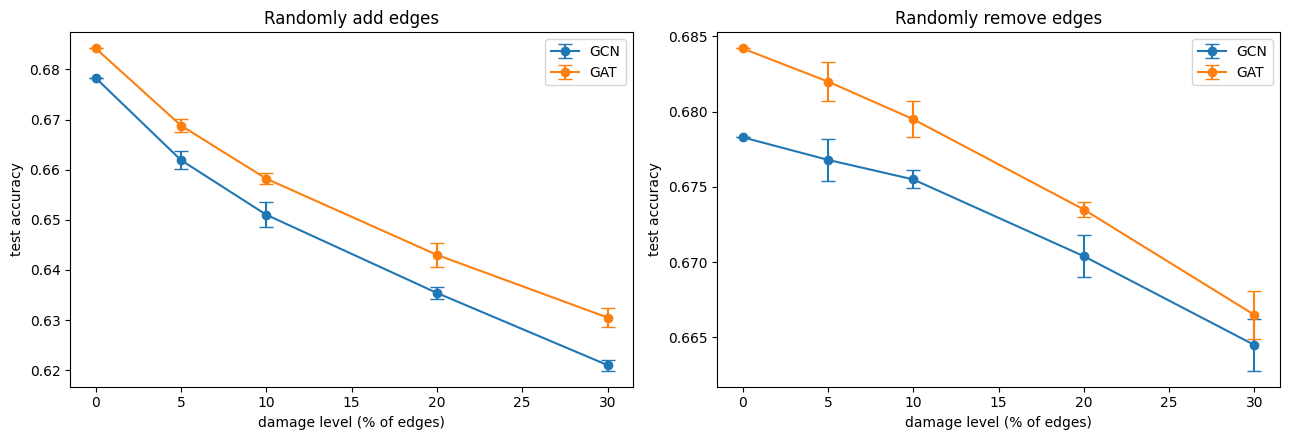

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, kind in zip(axes, ["add", "remove"]):
    for name in ["GCN", "GAT"]:
        s = robust[(robust.kind == kind) & (robust.model == name)].sort_values("level")
        ax.errorbar(s["level"] * 100, s["mean_acc"], yerr=np.nan_to_num(s["std_acc"]),
                    marker="o", capsize=5, label=name)
    ax.set_xlabel("damage level (% of edges)")
    ax.set_ylabel("test accuracy")
    ax.set_title(f"Randomly {kind} edges")
    ax.legend()

plt.tight_layout(); plt.show()

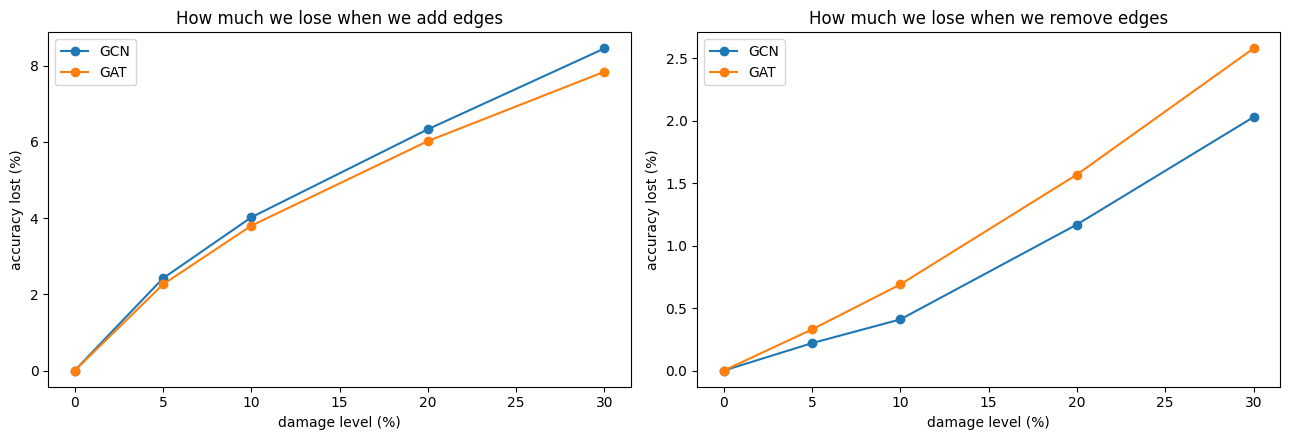

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, kind in zip(axes, ["add", "remove"]):
    for name in ["GCN", "GAT"]:
        s = robust[(robust.kind == kind) & (robust.model == name)].sort_values("level")
        ax.plot(s["level"] * 100, s["lost_percent"], marker="o", label=name)
    ax.set_xlabel("damage level (%)")
    ax.set_ylabel("accuracy lost (%)")
    ax.set_title(f"How much we lose when we {kind} edges")
    ax.legend()

plt.tight_layout(); plt.show()

**How to read these plots:**

- the **height** of a line shows how good the model is
- the **slope** shows how much the damage hurts it
- a model can start higher and still fall faster

## What happened to homophily?

We expect:

- adding random edges lowers homophily, because random pairs usually have different subjects
- removing edges keeps it about the same, because we remove good and bad edges equally

Let us check.

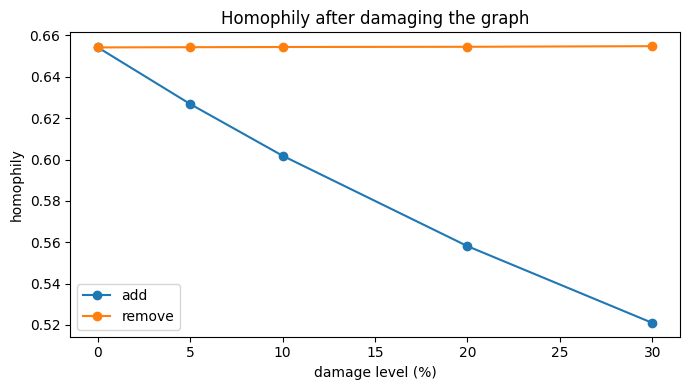

  kind  level   edges  homophily
   add   0.00 1157799     0.6542
   add   0.05 1215688     0.6268
   add   0.10 1273578     0.6018
   add   0.20 1389358     0.5581
   add   0.30 1505138     0.5210
remove   0.00 1157799     0.6542
remove   0.05 1099910     0.6543
remove   0.10 1042020     0.6544
remove   0.20  926240     0.6545
remove   0.30  810460     0.6548


In [19]:
plt.figure(figsize=(7, 4))
for kind in ["add", "remove"]:
    s = graph_table[graph_table.kind == kind].sort_values("level")
    plt.plot(s["level"] * 100, s["homophily"], marker="o", label=kind)
plt.xlabel("damage level (%)")
plt.ylabel("homophily")
plt.title("Homophily after damaging the graph")
plt.legend(); plt.tight_layout(); plt.show()

print(graph_table.to_string(index=False))

**Be careful here.** Lower homophily may go together with lower accuracy, but that does not prove
homophily is the cause. Adding edges changes several things at once: homophily goes down, the number
of neighbours goes up, and the work per epoch goes up. We cannot say which one did it.

## What does attention do with fake edges?

GAT gives every edge a weight, so we can ask directly:

> Does GAT give the fake edges a smaller weight than the real ones?

**One problem first.** The weights of one node's neighbours add up to 1. So a node with 100
neighbours has small weights everywhere, just because it has many. To compare fairly we divide each
weight by the equal share `1 / number of neighbours`.

Read the score like this:

- **around 1.0** -> normal share, GAT treats the edge like any other
- **below 1.0** -> GAT pushed the edge down
- **above 1.0** -> GAT pulled the edge up

We check **both layers** separately, and three groups of edges: real, fake, and self-loops (the
node's own message, which GAT adds by itself).

In [20]:
attention_level = max(LEVELS)
fake_now = fake_edges_at[attention_level]
noisy_edges, _ = damage_graph(base_edges, "add", attention_level, NOISE_SEED)
noisy_data = build_data(noisy_edges).to(device)

print(f"Using the graph with {attention_level:.0%} fake edges")
print("real edges:", f"{len(base_edges):,}", " fake edges:", f"{len(fake_now):,}")
print("same-subject share of real edges:", round(homophily(base_edges), 4))
print("same-subject share of fake edges:", round(homophily(fake_now), 4))
print()

# one GAT on the clean graph, one on the noisy graph, same seed
_, gat_clean = train("GAT", data, seed=0, graph_name="attention_clean")
_, gat_noisy = train("GAT", noisy_data, seed=0, graph_name="attention_noisy",
                     level=attention_level)
print("both models trained")

Using the graph with 30% fake edges
real edges: 1,157,799  fake edges: 347,339
same-subject share of real edges: 0.6542
same-subject share of fake edges: 0.077

both models trained


The fake edges almost never join two papers of the same subject. That is what makes them noise.

In [21]:
@torch.no_grad()
def attention_report(model, data, label):
    model.eval()
    _, attentions = model(data.x, data.edge_index, return_attention=True)

    rows = []
    for layer_number, (edge_index, alpha) in enumerate(attentions, start=1):
        src = edge_index[0].cpu().numpy().astype(np.int64)
        dst = edge_index[1].cpu().numpy().astype(np.int64)
        weight = alpha.mean(dim=1).cpu().numpy()          # average over the heads

        is_self = src == dst
        pair = np.minimum(src, dst) * num_nodes + np.maximum(src, dst)
        is_fake = np.isin(pair, fake_now) & ~is_self
        is_real = ~is_fake & ~is_self

        neighbours = np.bincount(dst, minlength=num_nodes)
        equal_share = 1.0 / np.maximum(neighbours[dst], 1)
        score = weight / equal_share

        for group, mask in [("real", is_real), ("fake", is_fake), ("self-loop", is_self)]:
            if mask.sum() == 0:
                continue
            rows.append({"graph": label, "layer": layer_number, "edges": group,
                         "count": int(mask.sum()), "score": round(float(score[mask].mean()), 3)})
    return pd.DataFrame(rows)


attention_table = pd.concat([
    attention_report(gat_clean, data, "clean"),
    attention_report(gat_noisy, noisy_data, "noisy"),
], ignore_index=True)

print("ATTENTION SCORE  (1.0 = equal share, below 1.0 = pushed down)")
print(attention_table.to_string(index=False))

ATTENTION SCORE  (1.0 = equal share, below 1.0 = pushed down)
graph  layer     edges   count  score
clean      1      real 2315598  0.999
clean      1 self-loop  169343  1.015
clean      2      real 2315598  1.001
clean      2 self-loop  169343  0.992
noisy      1      real 2315598  0.995
noisy      1      fake  694678  0.996
noisy      1 self-loop  169343  1.083
noisy      2      real 2315598  1.006
noisy      2      fake  694678  0.971
noisy      2 self-loop  169343  1.041


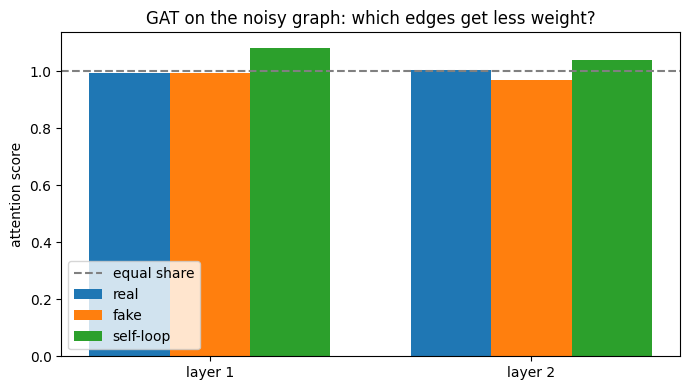

In [22]:
noisy_att = attention_table[attention_table.graph == "noisy"]
layers = sorted(noisy_att["layer"].unique())
groups = ["real", "fake", "self-loop"]
x = np.arange(len(layers))
width = 0.25

plt.figure(figsize=(7, 4))
for i, g in enumerate(groups):
    values = [noisy_att[(noisy_att.layer == l) & (noisy_att.edges == g)]["score"].mean()
              for l in layers]
    plt.bar(x + (i - 1) * width, values, width, label=g)

plt.axhline(1.0, color="grey", linestyle="--", label="equal share")
plt.xticks(x, [f"layer {l}" for l in layers])
plt.ylabel("attention score")
plt.title("GAT on the noisy graph: which edges get less weight?")
plt.legend(); plt.tight_layout(); plt.show()

In [23]:
fake_score = noisy_att[noisy_att.edges == "fake"].set_index("layer")["score"]
real_score = noisy_att[noisy_att.edges == "real"].set_index("layer")["score"]

for layer in layers:
    f, r = fake_score[layer], real_score[layer]
    print(f"Layer {layer}: real = {r:.3f}, fake = {f:.3f}", end="   ")
    if f < r * 0.9:
        print("-> fake edges got clearly less weight")
    elif f > r * 1.1:
        print("-> fake edges got MORE weight (not what we expected)")
    else:
        print("-> about the same, no clear difference")

Layer 1: real = 0.995, fake = 0.996   -> about the same, no clear difference
Layer 2: real = 1.006, fake = 0.971   -> about the same, no clear difference


**Careful with this result.**

- attention weights are **not** an explanation of the prediction
- they only say how much a message was used inside one layer
- a low weight does not prove the model "knew" the edge was fake